In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import make_pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted
from sklearn.impute import SimpleImputer

from pathlib import Path
from collections import Counter
import re

## Data Dictionary

Below is the description of the columns provided by the competition organizers:

| Variable | Definition | Key / Note |
| :--- | :--- | :--- |
| **survival** | Survival | `0` = No, `1` = Yes |
| **pclass** | Ticket class | `1` = 1st, `2` = 2nd, `3` = 3rd |
| **sex** | Sex | - |
| **Age** | Age in years | Requires missing value imputation |
| **sibsp** | # of siblings / spouses aboard the Titanic | - |
| **parch** | # of parents / children aboard the Titanic | - |
| **ticket** | Ticket number | String feature with high cardinality |
| **fare** | Passenger fare | Continuous numerical feature |
| **cabin** | Cabin number | High missing rate (potential for deck extraction) |
| **embarked** | Port of Embarkation | `C` = Cherbourg, `Q` = Queenstown, `S` = Southampton |

In [2]:
data_path = Path("data") / "train.csv"
titanic_train_data = pd.read_csv(data_path)

titanic_train_data = titanic_train_data.drop(columns="PassengerId")

### First look at the data

In [3]:
titanic_train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


In [5]:
titanic_train_data.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


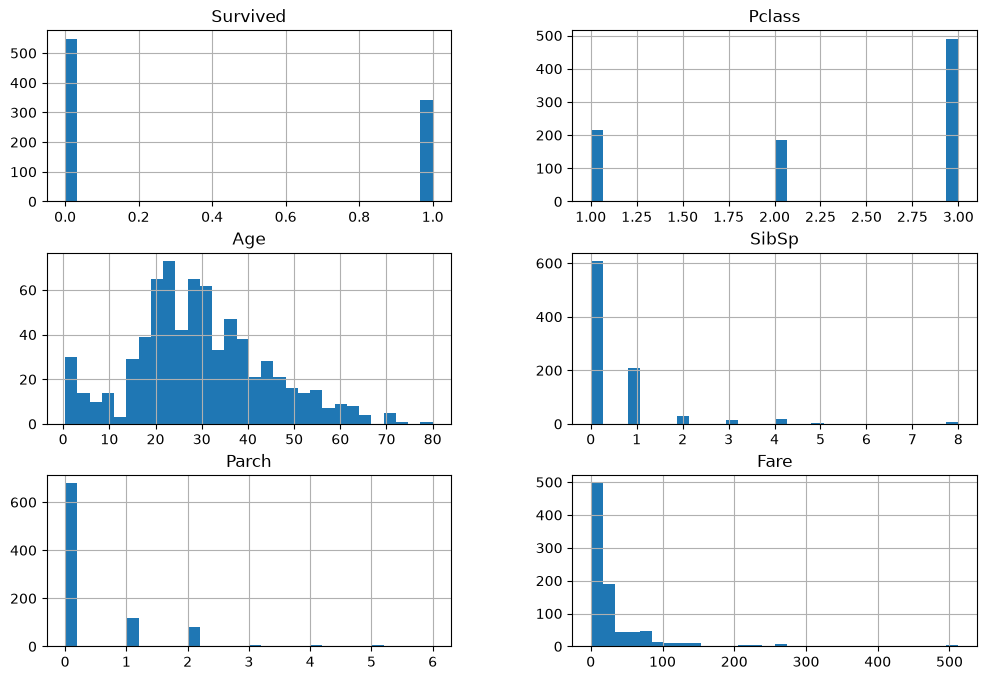

In [6]:
titanic_train_data.hist(bins=30, figsize=(12, 8))
plt.show()

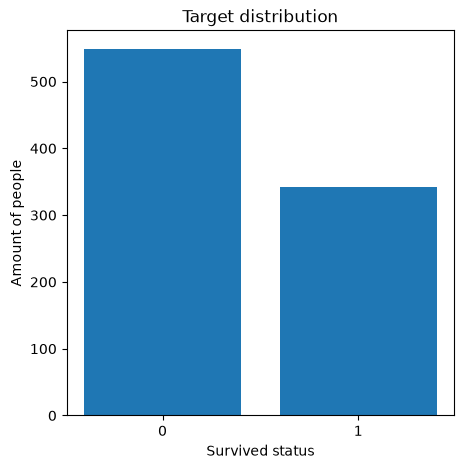

In [7]:
main_feature_distribution = titanic_train_data["Survived"].value_counts()

plt.figure(figsize=(5, 5))
plt.bar(
    x=main_feature_distribution.index,
    height=main_feature_distribution.values
)
plt.xticks(ticks=[0, 1])
plt.xlabel("Survived status")
plt.ylabel("Amount of people")
plt.title("Target distribution")

plt.show()

### Train/Test split

In [124]:
train_set, test_set = train_test_split(
    titanic_train_data, 
    test_size=0.2, 
    stratify=titanic_train_data["Survived"], 
    random_state=42
)

### EDA (Exploratory Data Analysis)

**Name**

The column name is composed of passengers names. We can use it in order to fill the age column by extracting the type of passenger and calculating the mean age of each group.

In [9]:
names_text = ', '.join(train_set["Name"].values).split(" ")
names_most_common_words = Counter(names_text)
print("Top 10 most common words in Name column is:")
for i in names_most_common_words.most_common(10):
    print(i[0], i[1])

Top 10 most common words in Name column is:
Mr. 412
Miss. 141
Mrs. 107
William 37
Master. 31
John 21
Henry 16
John, 15
Charles 14
Henry, 12


There are 5 groups inside this text:
- Mr
- Miss
- Mrs
- Master
- Other

We can create new feature "title" using this data, and then based on this information work with age column

In [10]:
patterns = r"(Mr\.|Mrs\.|Miss\.|Master\.)"

def passenger_types(X):
    return X.apply(lambda x: re.findall(patterns, x)[0][:-1] if re.findall(patterns, x) else "Other").to_frame(name="passenger_types")

def passenger_types_name(function_transformer, feature_names_in):
    return ["passenger_types"]

name_transformer = FunctionTransformer(
    passenger_types,
    feature_names_out=passenger_types_name
)
name_pipeline = make_pipeline(
    name_transformer,
    OneHotEncoder(handle_unknown="ignore")
)

# res = name_pipeline.fit_transform(titanic_train_data["Name"])
# res.toarray()

#### Numerical Features

**Age**

In [11]:
titanic_train_data_copy = titanic_train_data.copy()
titanic_train_data_copy.index.name = "index"
titanic_train_data_copy = titanic_train_data_copy.reset_index()
titanic_train_data_copy["Sex"] = titanic_train_data_copy["Sex"].map({"male": 0, "female": 1})

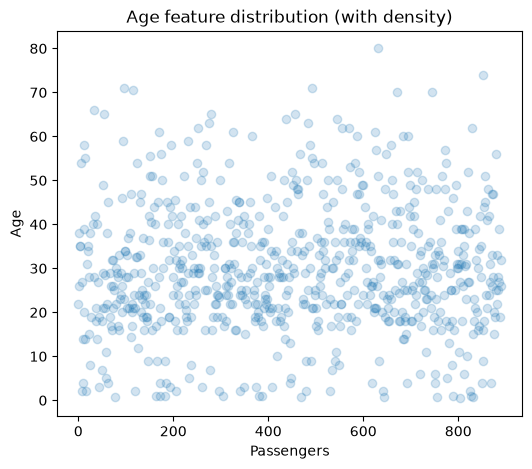

In [12]:
plt.figure(figsize=(6, 5))

plt.scatter(
    x=titanic_train_data.index,
    y=titanic_train_data["Age"],
    alpha=0.2
)

plt.xlabel("Passengers")
plt.ylabel("Age")
plt.title("Age feature distribution (with density)")

plt.show()

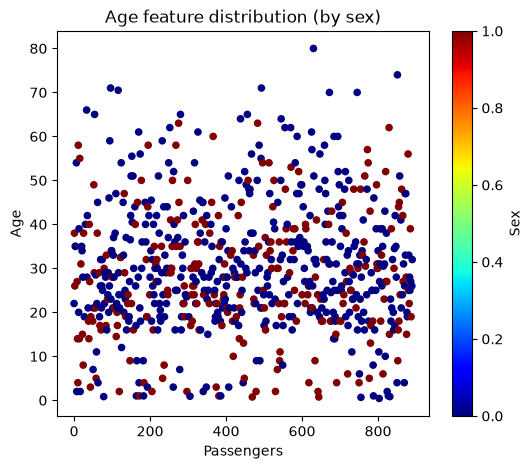

In [13]:
titanic_train_data_copy.plot(
    kind="scatter",
    x="index",
    y="Age",
    c="Sex",
    cmap="jet",
    figsize=(6, 5)
)
plt.xlabel("Passengers")
plt.ylabel("Age")
plt.title("Age feature distribution (by sex)")

plt.show()

In [21]:
class AgeFillEstimator(BaseEstimator, TransformerMixin):
    """
    Transforming Age using Name
    """

    def __init__(self, group_id=0, target_id=1):
        self.target_id = target_id
        self.group_id = group_id

    def fit(self, X, y=None):
        X_transform = X.copy()
        if not isinstance(X_transform, pd.DataFrame):
            X_transform = pd.DataFrame(X_transform, columns=["Group", "Target"])
        cols = X_transform.columns
        X_transform = pd.concat([X_transform, passenger_types(X_transform[cols[self.group_id]])], axis=1)

        cleaned_target = X_transform[cols[self.target_id]].replace(0, np.nan)
        
        self.age_means = X_transform.groupby(by="passenger_types")[cols[self.target_id]].apply(
            lambda x: x.replace(0, np.nan).mean()
        ).round(0)
        
        self.global_age_median = cleaned_target.median()
        
        return self

    def transform(self, X):
        X_transform = X.copy()
        if not isinstance(X, pd.DataFrame):
            X_transform = pd.DataFrame(X_transform, columns=["Group", "Target"])
            
        cols = X_transform.columns
        X_transform = pd.concat([X_transform, passenger_types(X_transform[cols[self.group_id]])], axis=1)
        
        X_transform["temp_col"] = X_transform["passenger_types"].map(self.age_means)
        X_transform["temp_col"] = X_transform["temp_col"].fillna(self.global_age_median)
        
        filled_age = X_transform[cols[self.target_id]].where(
            (X_transform[cols[self.target_id]] != 0) & (~X_transform[cols[self.target_id]].isna()),
            X_transform["temp_col"]
        )
        
        return filled_age.values.reshape(-1, 1)

    def get_feature_names_out(self, names=None):
        return ["filled_age"]

# age_estimator = AgeFillEstimator()
# example_new_feature_values = age_estimator.fit_transform(titanic_train_data_copy[["Name", "Age"]].values)
# age_pipeline.fit_transform(titanic_train_data_copy[["Name", "Age"]].values)

**Fare**

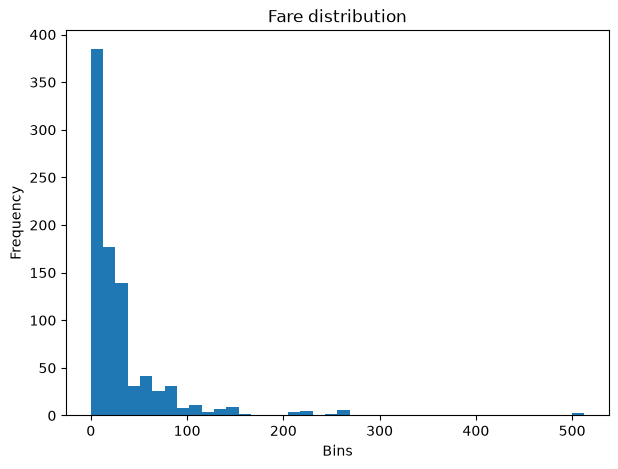

In [22]:
plt.figure(figsize=(7, 5))

plt.hist(
    x=titanic_train_data_copy["Fare"],
    bins=40
)
plt.xlabel("Bins")
plt.ylabel("Frequency")
plt.title("Fare distribution")

plt.show()

The Fare feature has a heavy tail to the right. We can use logarithm in order to edit this data

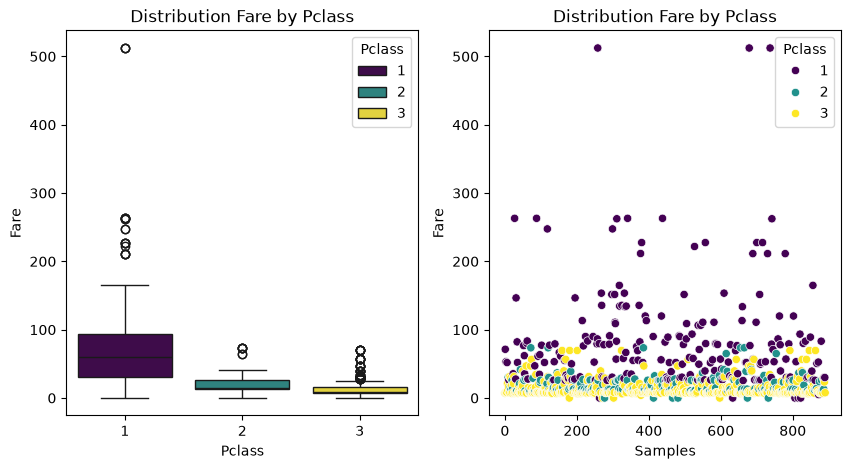

In [23]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,5))

sns.boxplot(
    ax=axes[0],
    data=titanic_train_data_copy,
    x="Pclass",
    y="Fare",
    hue="Pclass",
    palette="viridis"
)
axes[0].set_title("Distribution Fare by Pclass")
axes[0].set_xlabel("Pclass")
axes[0].set_ylabel("Fare")

sns.scatterplot(
    data=titanic_train_data_copy,
    x=titanic_train_data_copy.index,
    y="Fare",
    hue="Pclass",
    palette="viridis"
)
axes[1].set_title("Distribution Fare by Pclass")
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Fare")

plt.show()

The most expensive class is 1. The median in this class is upper than others. Nevertheless, the samples of cheap 1 class can be seen at the second diagram.

In [24]:
titanic_train_data_copy["Fare"].sort_values(ascending=True)

815      0.0000
806      0.0000
413      0.0000
481      0.0000
302      0.0000
         ...   
438    263.0000
341    263.0000
737    512.3292
679    512.3292
258    512.3292
Name: Fare, Length: 891, dtype: float64

In [25]:
titanic_train_data_copy.loc[titanic_train_data_copy["Fare"] > 0].sort_values(by="Fare", ascending=True)

,index,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
378,378,0,3,"Betros, Mr. Tannous",0,20.0,0,0,2648,4.0125,NaN,C
872,872,0,1,"Carlsson, Mr. Frans Olof",0,33.0,0,0,695,5.0000,B51 B53 B55,S
326,326,0,3,"Nysveen, Mr. Johan Hansen",0,61.0,0,0,345364,6.2375,NaN,S
843,843,0,3,"Lemberopolous, Mr. Peter L",0,34.5,0,0,2683,6.4375,NaN,C
818,818,0,3,"Holm, Mr. John Fredrik Alexander",0,43.0,0,0,C 7075,6.4500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
88,88,1,1,"Fortune, Miss. Mabel Helen",1,23.0,3,2,19950,263.0000,C23 C25 C27,S
27,27,0,1,"Fortune, Mr. Charles Alexander",0,19.0,3,2,19950,263.0000,C23 C25 C27,S
737,737,1,1,"Lesurer, Mr. Gustave J",0,35.0,0,0,PC 17755,512.3292,B101,C
679,679,1,1,"Cardeza, Mr. Thomas Drake Martinez",0,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C


In [26]:
titanic_train_data_copy.loc[titanic_train_data_copy["Fare"] == 0]

,index,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
179,179,0,3,"Leonard, Mr. Lionel",0,36.0,0,0,LINE,0.0,NaN,S
263,263,0,1,"Harrison, Mr. William",0,40.0,0,0,112059,0.0,B94,S
271,271,1,3,"Tornquist, Mr. William Henry",0,25.0,0,0,LINE,0.0,NaN,S
277,277,0,2,"Parkes, Mr. Francis ""Frank""",0,NaN,0,0,239853,0.0,NaN,S
302,302,0,3,"Johnson, Mr. William Cahoone Jr",0,19.0,0,0,LINE,0.0,NaN,S
413,413,0,2,"Cunningham, Mr. Alfred Fleming",0,NaN,0,0,239853,0.0,NaN,S
466,466,0,2,"Campbell, Mr. William",0,NaN,0,0,239853,0.0,NaN,S
481,481,0,2,"Frost, Mr. Anthony Wood ""Archie""",0,NaN,0,0,239854,0.0,NaN,S
597,597,0,3,"Johnson, Mr. Alfred",0,49.0,0,0,LINE,0.0,NaN,S
633,633,0,1,"Parr, Mr. William Henry Marsh",0,NaN,0,0,112052,0.0,NaN,S


Also there are 15 people who have tickets with price equal to zero. there are all types of classes whithin this group of people and all of them embarked from the same area.

In [32]:
class FareFillEstimator(BaseEstimator, TransformerMixin):

    def __init__(self, group_id=0, target_id=1):
        self.group_id = group_id
        self.target_id = target_id

    def fit(self, X, y=None):
        X_transform = X.copy()
        if not isinstance(X_transform, pd.DataFrame):
            X_transform = pd.DataFrame(X_transform, columns=["Group", "Target"])
        cols = X_transform.columns
        cleaned_target = X_transform[cols[self.target_id]].replace(0, np.nan)
        self.fare_means = X_transform.groupby(by=cols[self.group_id])[cols[self.target_id]].apply(
            lambda x: x.replace(0, np.nan).median()
        )
        self.global_fare_median = cleaned_target.median()
        
        return self

    def transform(self, X):
        X_transform = X.copy()
        if not isinstance(X_transform, pd.DataFrame):
            X_transform = pd.DataFrame(X_transform, columns=["Group", "Target"])
        cols = X_transform.columns
        
        X_transform["temp_col"] = X_transform[cols[self.group_id]].map(self.fare_means)
        X_transform["temp_col"] = X_transform["temp_col"].fillna(self.global_fare_median)
        
        filled_fare = X_transform[cols[self.target_id]].where(
            (X_transform[cols[self.target_id]] != 0) & (~X_transform[cols[self.target_id]].isna()),
            X_transform["temp_col"]
        )

        return filled_fare.values.reshape(-1, 1)

    def get_feature_names_out(self, names=None):
        return ["fare_filled"]


fare_transformer = FunctionTransformer(np.log, feature_names_out="one-to-one")

fare_pipeline = make_pipeline(
    FareFillEstimator(),
    fare_transformer,
    StandardScaler()
)

# fare_pipeline.fit_transform(titanic_train_data_copy[["Pclass", "Fare"]].values)

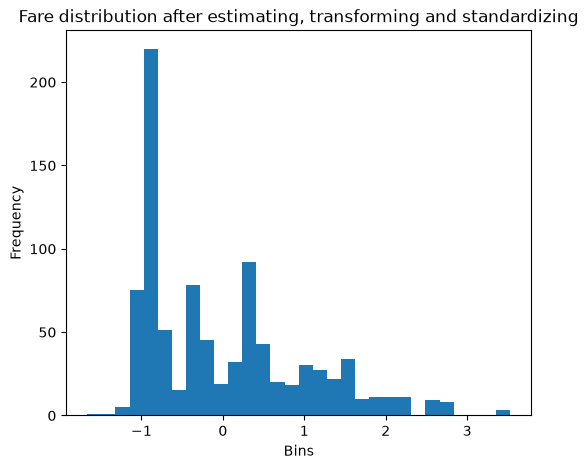

In [80]:
f_pip = fare_pipeline.fit_transform(titanic_train_data_copy[["Pclass", "Fare"]].values)

plt.figure(figsize=(6, 5))

plt.hist(
    x=f_pip.flatten(),
    bins=30,
)
plt.title("Fare distribution after estimating, transforming and standardizing")
plt.xlabel("Bins")
plt.ylabel("Frequency")

plt.show()

Now all three classes can be easily seen

**SibSp and Parch**

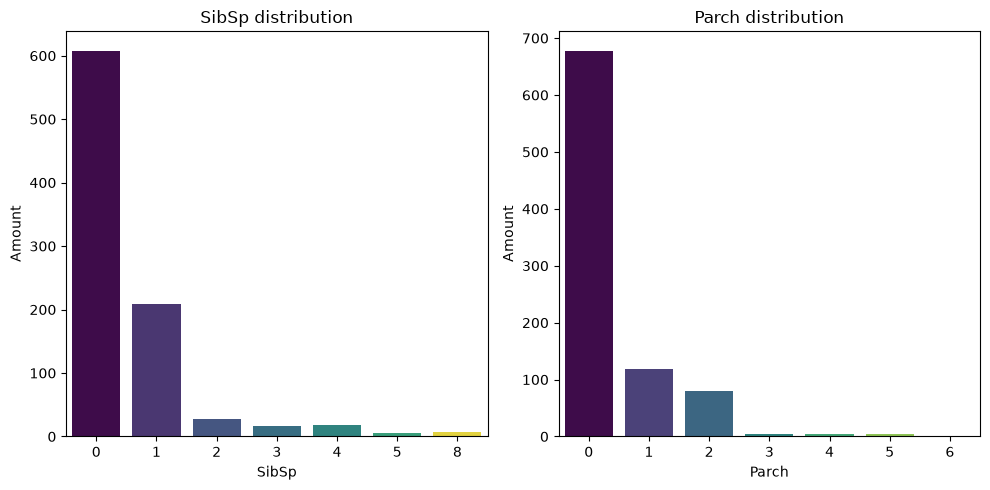

In [67]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

sns.countplot(
    ax=axes[0],
    data=titanic_train_data_copy,
    x="SibSp",
    palette="viridis",
    hue="SibSp",
    legend=False,
)
axes[0].set_title("SibSp distribution")
axes[0].set_ylabel("Amount")

sns.countplot(
    ax=axes[1],
    data=titanic_train_data_copy,
    x="Parch",
    palette="viridis",
    hue="Parch",
    legend=False
)
axes[1].set_title("Parch distribution")
axes[1].set_ylabel("Amount")

fig.tight_layout()

plt.show()

Two numerical features show the amount of relatives. Combine them by adding one to the other and therefore reduce the dimensionality

In [79]:
def sibsp_parch_combine(X):
    if isinstance(X, pd.DataFrame):
        X = X.to_numpy()
    combined = X[:, 0] + X[:, 1] + 1

    return combined.reshape(-1, 1)

def sibsp_parch_combine_name(function_transformer, feature_names_in):
    return ["family_size"]

def sibsp_parch_pipeline():
    return make_pipeline(
        FunctionTransformer(sibsp_parch_combine, feature_names_out=sibsp_parch_combine_name),
        StandardScaler()
    )

# res = sibsp_parch_combine(titanic_train_data_copy[["Parch", "SibSp"]].values)

**Pclass and Sex**

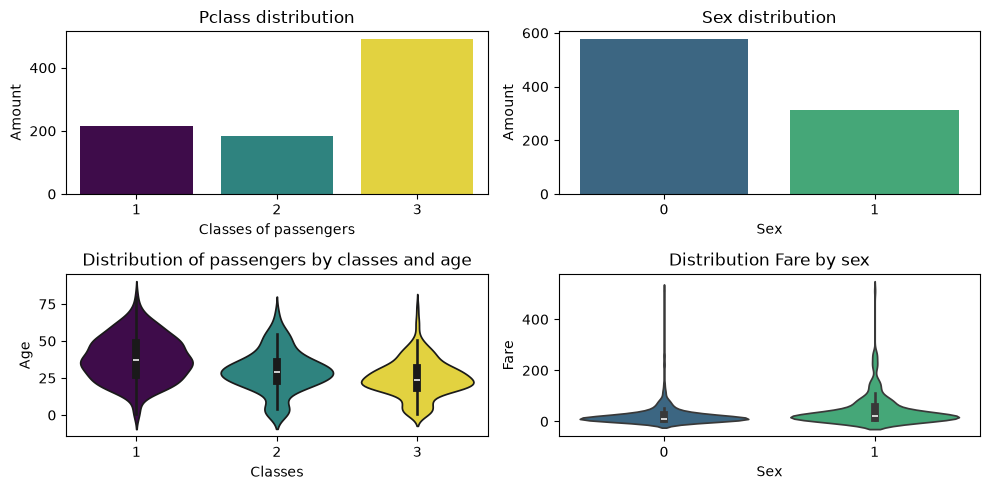

In [111]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 5))

sns.countplot(
    data=titanic_train_data_copy,
    ax=axes[0][0],
    x="Pclass",
    palette="viridis",
    hue="Pclass",
    legend=False
)
axes[0][0].set_title("Pclass distribution")
axes[0][0].set_xlabel("Classes of passengers")
axes[0][0].set_ylabel("Amount")

sns.countplot(
    data=titanic_train_data_copy,
    ax=axes[0][1],
    x="Sex",
    palette="viridis",
    hue="Sex",
    legend=False
)
axes[0][1].set_title("Sex distribution")
axes[0][1].set_xlabel("Sex")
axes[0][1].set_ylabel("Amount")

sns.violinplot(
    data=titanic_train_data_copy,
    ax=axes[1][0],
    x="Pclass",
    y="Age",
    palette="viridis",
    hue="Pclass",
    legend=False
)
axes[1][0].set_title("Distribution of passengers by classes and age")
axes[1][0].set_xlabel("Classes")
axes[1][0].set_ylabel("Age")

sns.violinplot(
    data=titanic_train_data_copy,
    ax=axes[1][1],
    x="Sex", 
    y="Fare",
    palette="viridis",
    hue="Sex",
    legend=False
)
axes[1][1].set_title("Distribution Fare by sex")
axes[1][1].set_xlabel("Sex")
axes[1][1].set_ylabel("Fare")

fig.tight_layout()

plt.show()

- The majority of passengers is men.
- The most common class is 3
- The third class passengers are mostly concentrated at 25 years. The second class passengers are mostly concentrated at 30. And the first class passengers mostly concentrated at 40.
- The values of fare paid by men and women are almost at the same level, but women spend a bit more

In [147]:
def passengers_sex_map(X):
    if isinstance(X, pd.DataFrame):
        X = X.iloc[:, 0]
    elif isinstance(X, np.ndarray):
        X = pd.Series(X.ravel())
        
    mapped = X.map({"male": 0, "female": 1})
    return mapped.to_frame()

def passengers_sex_map_name(function_transformer, feature_names_in):
    return ["sex"]

passenger_sex_pipeline = make_pipeline(
    FunctionTransformer(passengers_sex_map, feature_names_out=passengers_sex_map_name)
)

**Embarked**

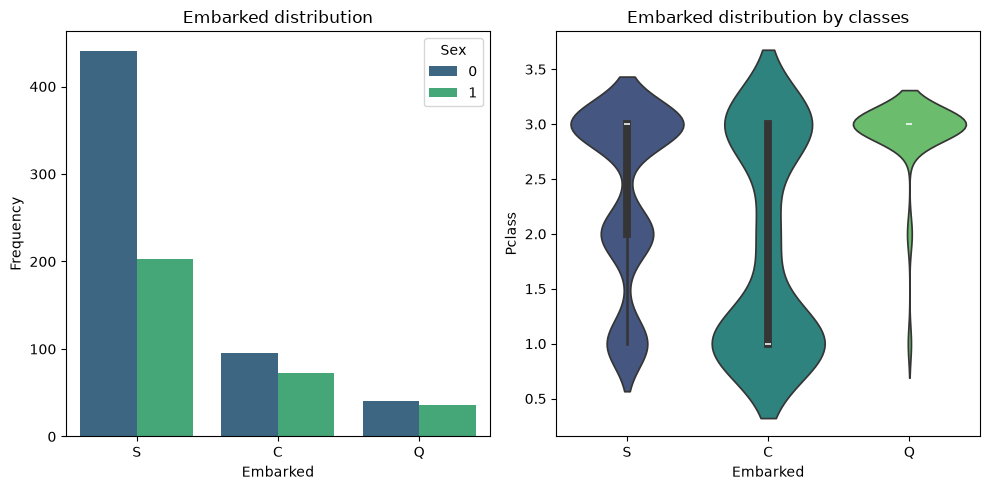

In [172]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

sns.countplot(
    data=titanic_train_data_copy,
    ax=axes[0],
    x="Embarked",
    palette="viridis",
    hue="Sex",
    legend=True
)
axes[0].set_title("Embarked distribution")
axes[0].set_xlabel("Embarked")
axes[0].set_ylabel("Frequency")

sns.violinplot(
    data=titanic_train_data_copy,
    ax=axes[1],
    x="Embarked",
    y="Pclass",
    palette="viridis",
    hue="Embarked",
    legend=False
)
axes[1].set_title("Embarked distribution by classes")
axes[1].set_xlabel("Embarked")
axes[1].set_ylabel("Pclass")

fig.tight_layout()

plt.show()

- The passengers majority arrived from "S"
- The main part of passengers from "C" are passengers of first and third class
- Almost all passengers from "Q" are passengers of 3 class
- The majority of passengers from "S" are passengers of third class, also the rest of passengers that class have been distributed between first and second class

In [182]:
embarked_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)
# res = embarked_pipeline.fit_transform(titanic_train_data_copy[["Embarked"]])